# Mouse growth-rate panels

Compare growth rates from the trained WFR and only-growth models.

## Growth-rate comparison

In [109]:
import torch


# Load the time-indexed dataset for this experiment.
data_name = 'mouse_hematopoiesis'


In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


data = pd.read_csv(f'data/{data_name}.csv')
t = np.array(data)[:, 0]
X = np.array(data)[:, 1:]


In [111]:
# Load the two trained models used in the panel comparison.
wfr = torch.load('mouse_hematopoiesis_flow_model_growth_wfr.pth',map_location='cpu',weights_only=False)
sudo = torch.load('mouse_hematopoiesis_flow_model_growth_only_growth.pth',map_location='cpu',weights_only=False)


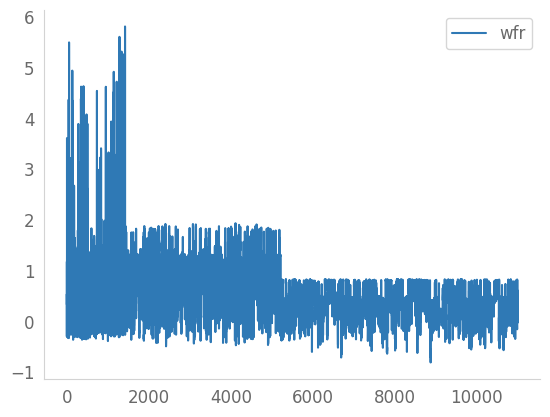

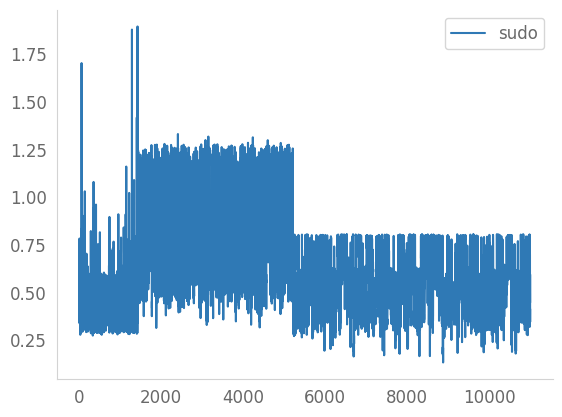

In [112]:
v_wfr,_,g_wfr = wfr(torch.tensor(X, dtype = torch.float32),torch.tensor(t, dtype = torch.float32).reshape(-1, 1))
g_wfr = g_wfr.detach().numpy()
v_wfr = v_wfr.detach().numpy()

plt.plot(g_wfr,label='wfr')
plt.legend()
plt.show()

v_sudo,_,g_sudo = sudo(torch.tensor(X, dtype = torch.float32),torch.tensor(t, dtype = torch.float32).reshape(-1, 1))
g_sudo = g_sudo.detach().numpy()
v_sudo = v_sudo.detach().numpy()

plt.plot(g_sudo,label='sudo')
plt.legend()
plt.show()


In [113]:
import seaborn as sns
# Plot a growth-rate field on the observed cell coordinates.
def g_plot(g,X1,X2,save=None,vmin=None,vmax=None,label=None,x=0.95,y=0.95):
    palette = 'RdBu_r'
    cmap = plt.cm.RdBu_r
    sns.set_palette(palette)
    plt.rcParams.update({
        'axes.axisbelow': False,
        'axes.edgecolor': 'lightgrey',
        'axes.facecolor': 'None',
        'axes.grid': False,
        'axes.labelcolor': 'dimgrey',
        'axes.spines.right': False,
        'axes.spines.top': False,
        'figure.facecolor': 'white',
        'lines.solid_capstyle': 'round',
        'patch.edgecolor': 'w',
        'patch.force_edgecolor': True,
        'text.color': 'dimgrey',
        'xtick.bottom': False,
        'xtick.color': 'dimgrey',
        'xtick.direction': 'out',
        'xtick.top': False,
        'ytick.color': 'dimgrey',
        'ytick.direction': 'out',
        'ytick.left': False,
        'ytick.right': False,
        'font.size':12,
        'axes.titlesize':10,
        'axes.labelsize':12
    })
    plt.figure(figsize=(12, 8))
    if vmin and vmax:
        plt.scatter(X1, X2, c=g, s=100, cmap=cmap, vmin=vmin, vmax=vmax)
    else:
        plt.scatter(X1, X2, c=g, s=100, cmap=cmap, vmin=vmin, vmax=vmax)

    plt.text(x=x, y=y, s=label, fontsize=45, color='black', ha='right', va='top', transform=plt.gca().transAxes)

    plt.xlabel("$X_1$", fontsize=30)
    plt.ylabel("$X_2$", fontsize=30)
    plt.xticks([])
    plt.yticks([])

    cbar = plt.colorbar()

    cbar.set_label('Growth Rate', fontsize=40)
    cbar.ax.tick_params(labelsize=30)


    if save:
        plt.savefig(save)
    plt.show()


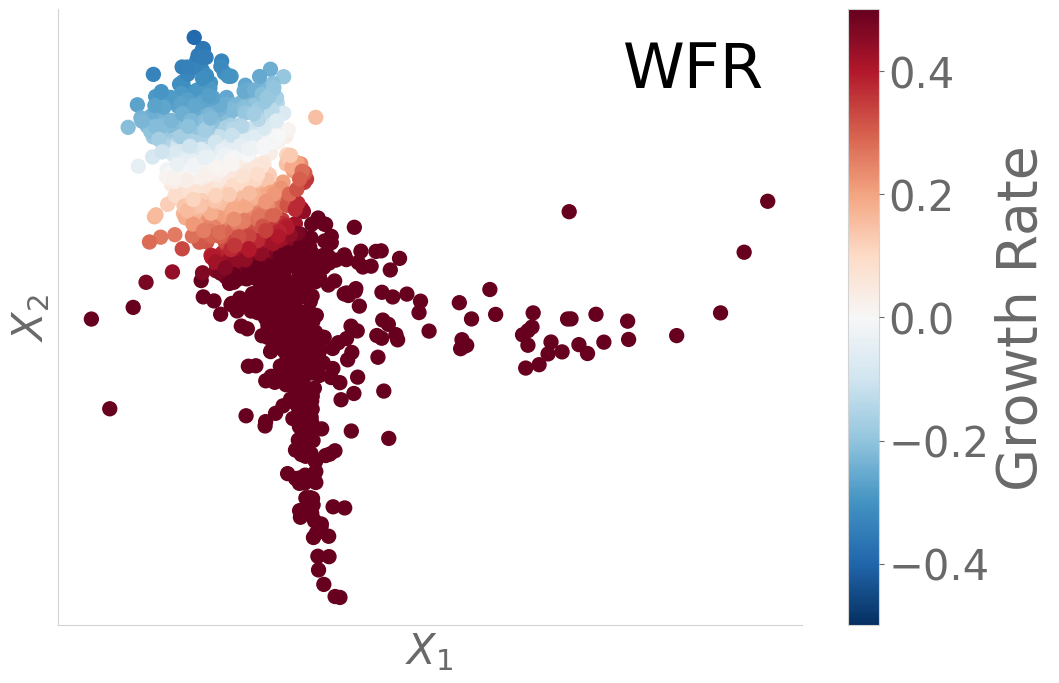

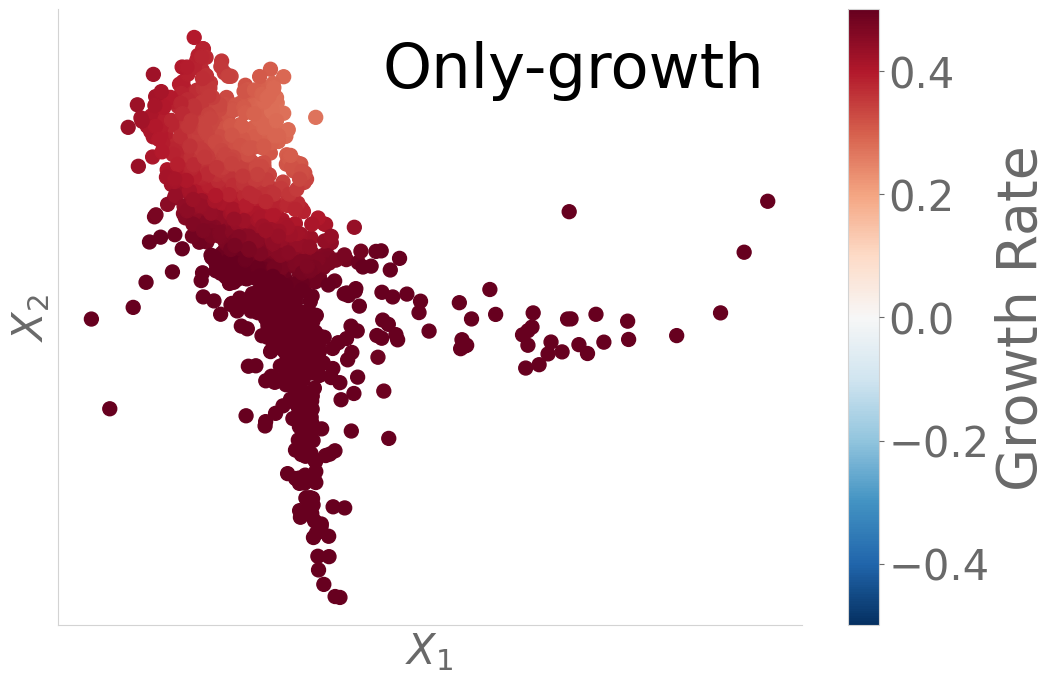

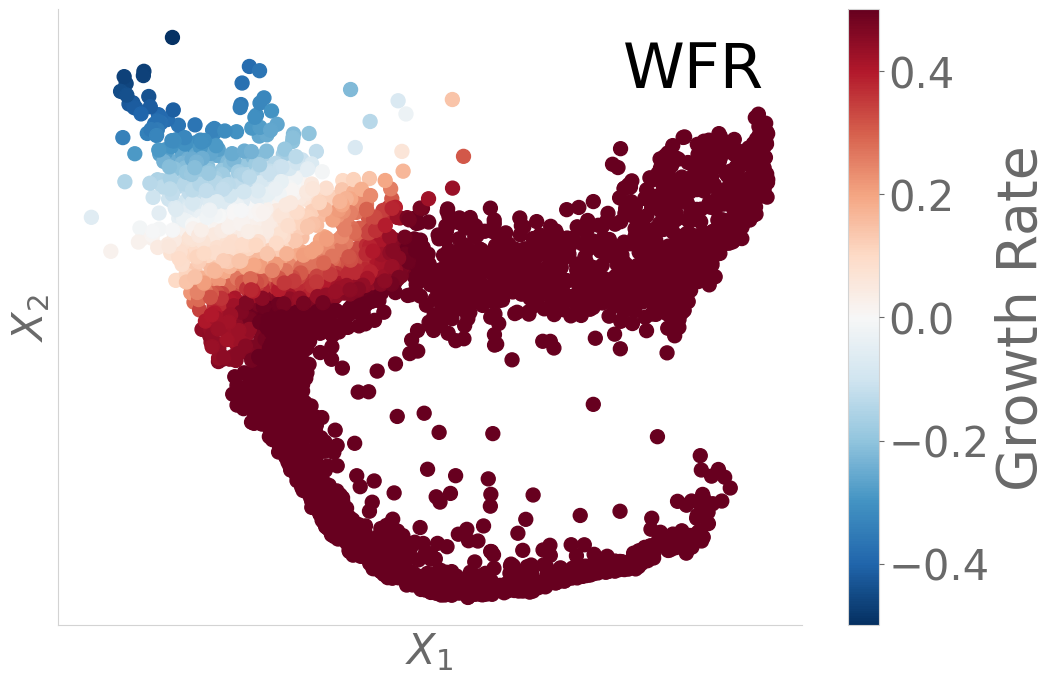

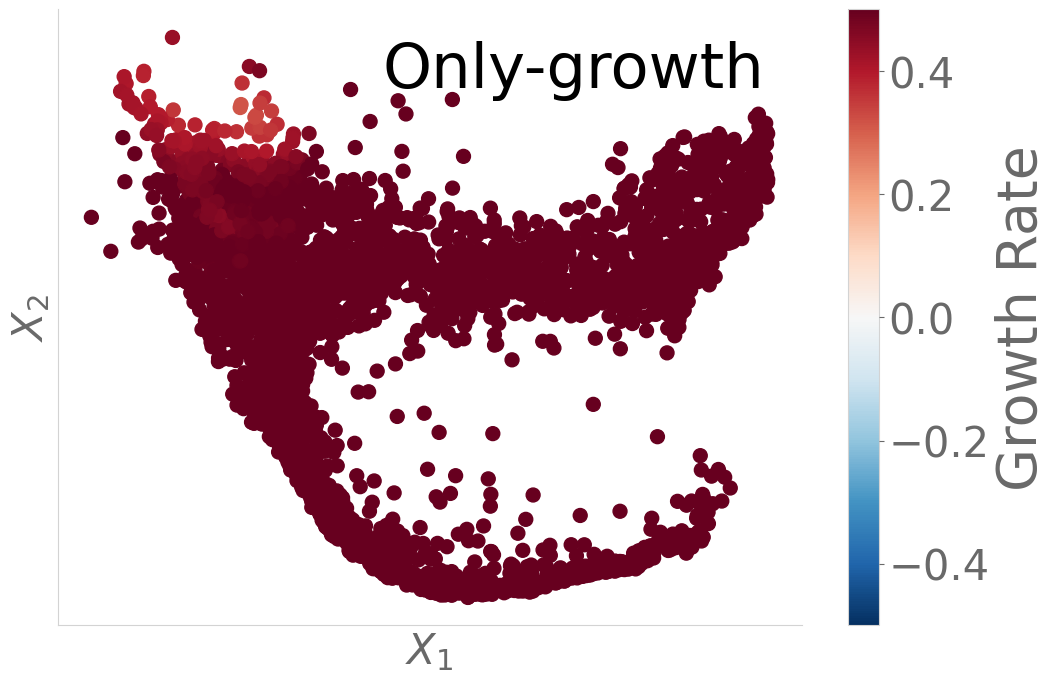

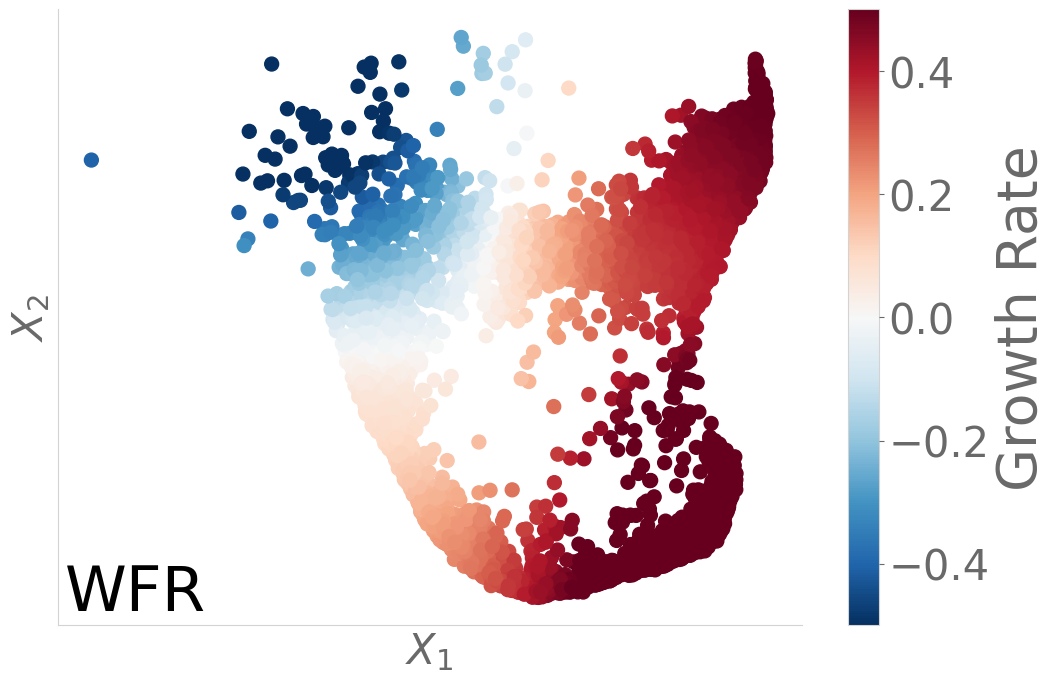

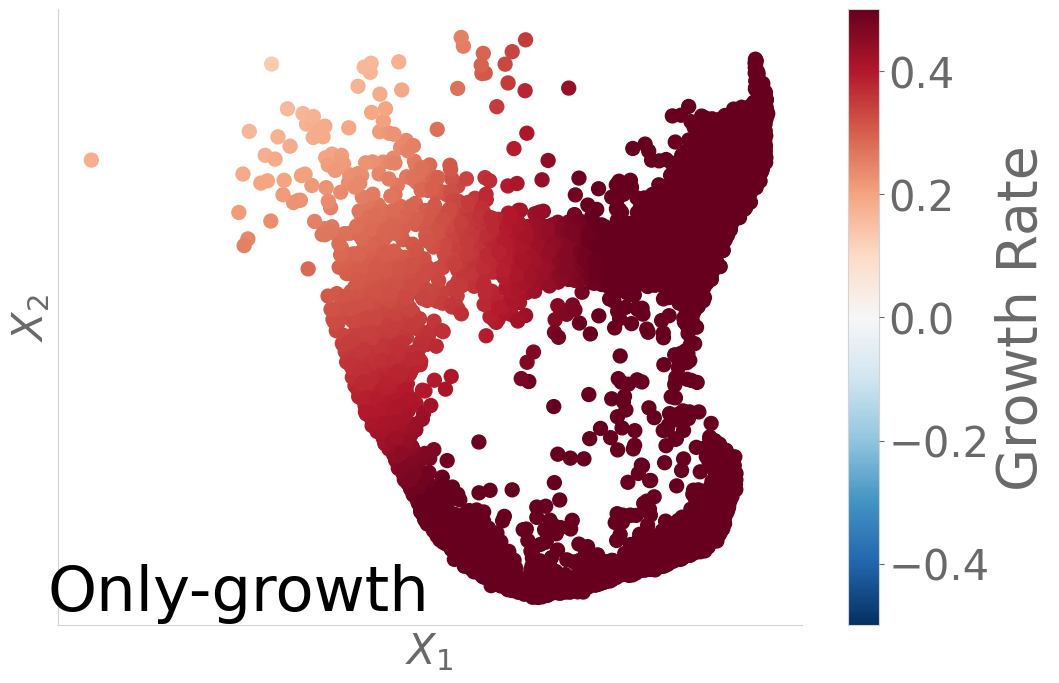

In [114]:
X1 = X[:,0]
X2 = X[:,1]

vmin = min(np.min(g_wfr[t==0]),np.min(g_sudo[t==0]))
vmax = max(np.max(g_wfr[t==0]),np.max(g_sudo[t==0]))
g_plot(g_wfr[t==0],X1[t==0],X2[t==0],save='real_data_growth_0_wfr.png',vmin=-0.5,vmax=0.5,label='WFR',x=0.95,y=0.95)
g_plot(g_sudo[t==0],X1[t==0],X2[t==0],save='real_data_growth_0_growth.png',vmin=-0.5,vmax=0.5,label='Only-growth',x=0.95,y=0.95)

vmin = min(np.min(g_wfr[t==1]),np.min(g_sudo[t==1]))
vmax = max(np.max(g_wfr[t==1]),np.max(g_sudo[t==1]))
g_plot(g_wfr[t==1],X1[t==1],X2[t==1],save='real_data_growth_1_wfr.png',vmin=-0.5,vmax=0.5,label='WFR',x=0.95,y=0.95)
g_plot(g_sudo[t==1],X1[t==1],X2[t==1],save='real_data_growth_1_growth.png',vmin=-0.5,vmax=0.5,label='Only-growth',x=0.95,y=0.95)

vmin = min(np.min(g_wfr[t==2]),np.min(g_sudo[t==2]))
vmax = max(np.max(g_wfr[t==2]),np.max(g_sudo[t==2]))
g_plot(g_wfr[t==2],X1[t==2],X2[t==2],save='real_data_growth_2_wfr.png',vmin=-0.5,vmax=0.5,label='WFR',x=0.2,y=0.1)
g_plot(g_sudo[t==2],X1[t==2],X2[t==2],save='real_data_growth_2_growth.png',vmin=-0.5,vmax=0.5,label='Only-growth',x=0.5,y=0.1)
